# Surface Crack Classification —  ResNet-18 Pipeline

**Objective:** Compare a pretrained ResNet-18 with a newly initialized classification head **before and after fine-tuning**, using the same untouched test split and evaluation function.

**Dataset:** `arunrk7/surface-crack-detection` (Kaggle). 3,000 balanced images; 70% train / 15% validation / 15% test.

**contribution:** random class-balanced sampling, reproducible stratified splitting, split/duplicate checks, consistent evaluation, learning curves, test-set metrics.


In [ ]:
# Cell 1 — Reproducible setup and balanced dataset selection
# Uncomment this line if kagglehub is not installed in your Colab environment.
# %pip -q install kagglehub

import os
import random
import time
import hashlib
from collections import Counter

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import kagglehub

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

SEED = 42
SAMPLES_PER_CLASS = 1500
BATCH_SIZE = 32
EPOCHS = 4
LEARNING_RATE = 1e-4

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Deterministic algorithms can be slower; these settings improve repeatability.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

# Download the Kaggle dataset and locate the folder containing class subfolders.
dataset_path = kagglehub.dataset_download('arunrk7/surface-crack-detection')
data_dir = None
for root, dirs, _ in os.walk(dataset_path):
    if {'Positive', 'Negative'}.issubset(set(dirs)):
        data_dir = root
        break
if data_dir is None:
    raise FileNotFoundError('Could not locate Positive and Negative folders.')

# ResNet-18 pretrained on ImageNet expects ImageNet normalization.
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])
raw_dataset = datasets.ImageFolder(root=data_dir, transform=transform)
class_names = raw_dataset.classes
assert class_names == ['Negative', 'Positive'], f'Unexpected class order: {class_names}'


# Randomly select a balanced dataset without exact duplicate images.
# SHA-256 hashes are used to detect identical file content.

rng = random.Random(SEED)

indices_by_class = {
    label: [
        i for i, (_, y) in enumerate(raw_dataset.samples)
        if y == label
    ]
    for label in range(len(class_names))
}

def content_hash(index):
    """Calculate the SHA-256 hash of an image file."""
    path, _ = raw_dataset.samples[index]
    digest = hashlib.sha256()

    with open(path, "rb") as image_file:
        for chunk in iter(
            lambda: image_file.read(1024 * 1024), b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


selected_indices = []
seen_hashes = set()
duplicate_count = 0

for label in range(len(class_names)):
    candidates = indices_by_class[label].copy()
    rng.shuffle(candidates)

    chosen = 0

    for index in candidates:
        file_hash = content_hash(index)

        # Skip images that have already been selected.
        if file_hash in seen_hashes:
            duplicate_count += 1
            continue

        seen_hashes.add(file_hash)
        selected_indices.append(index)
        chosen += 1

        if chosen == SAMPLES_PER_CLASS:
            break

    # Verify that enough unique images were found.
    if chosen < SAMPLES_PER_CLASS:
        raise ValueError(
            f"Not enough unique images in {class_names[label]}."
        )

# Shuffle the final balanced subset.
rng.shuffle(selected_indices)

selected_labels = [
    raw_dataset.targets[i] for i in selected_indices
]

print('Classes:', class_names)
print('Full dataset size:', len(raw_dataset))
print('Selected subset size:', len(selected_indices))
print('Selected class counts:', dict(Counter(selected_labels)))
print('Exact duplicates skipped:', duplicate_count)


Using device: cuda
Using Colab cache for faster access to the 'surface-crack-detection' dataset.
Classes: ['Negative', 'Positive']
Full dataset size: 40000
Selected subset size: 3000
Selected class counts: {0: 1500, 1: 1500}
Exact duplicates skipped: 10


Exact cross-split duplicate check passed.
Important: visually similar images may still occur in different splits.
Train: 2100 images; class counts: {0: 1050, 1: 1050}
Validation: 450 images; class counts: {0: 225, 1: 225}
Test: 450 images; class counts: {1: 225, 0: 225}


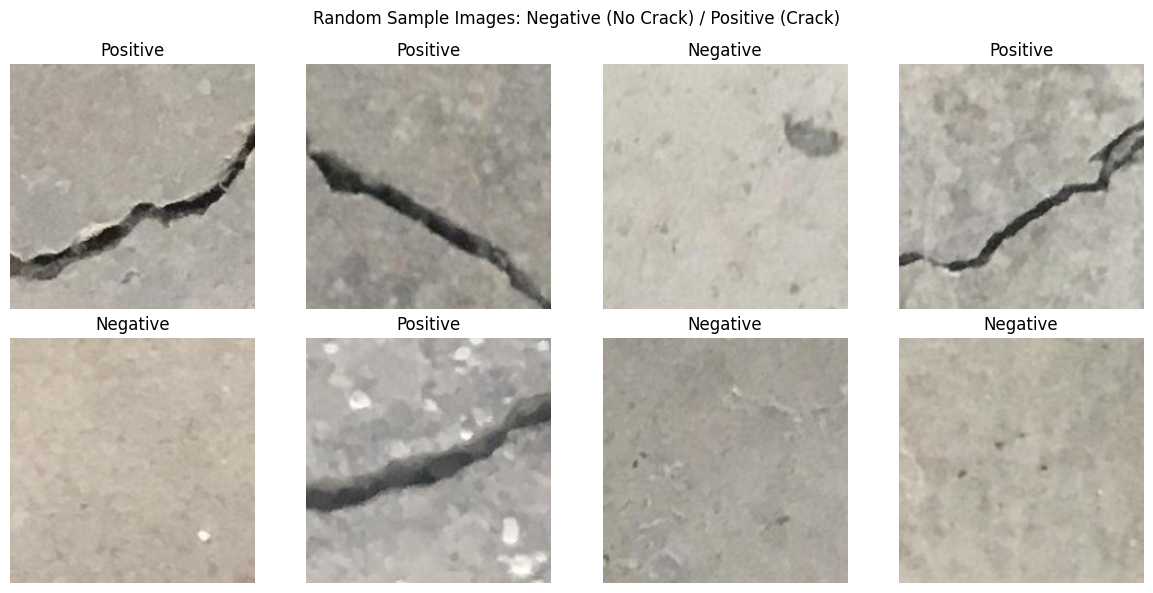

In [ ]:

# Cell 2 — Stratified train/validation/test split and leakage checks
# Stratification preserves the class distribution across all subsets.
# Verify that no identical image files exist across the data splits.
# The same held-out test set is evaluated before and after training (two required checkpoints)

train_idx, holdout_idx, train_y, holdout_y = train_test_split(
    selected_indices, selected_labels, test_size=0.30,
    stratify=selected_labels, random_state=SEED
)
val_idx, test_idx, val_y, test_y = train_test_split(
    holdout_idx, holdout_y, test_size=0.50,
    stratify=holdout_y, random_state=SEED
)

# An image index must never appear in two splits.
assert len(set(train_idx) & set(val_idx)) == 0
assert len(set(train_idx) & set(test_idx)) == 0
assert len(set(val_idx) & set(test_idx)) == 0
assert len(train_idx) + len(val_idx) + len(test_idx) == len(selected_indices)



hash_sets = [set(map(content_hash, indices)) for indices in (train_idx, val_idx, test_idx)]
for left, right, pair in [(0, 1, 'train/validation'),
                          (0, 2, 'train/test'),
                          (1, 2, 'validation/test')]:
    overlap = hash_sets[left] & hash_sets[right]
    if overlap:
        raise ValueError(f'{len(overlap)} identical image files occur in {pair}. '
                         'Remove duplicate images or create a group-based split.')
print('Exact cross-split duplicate check passed.')
print('Important: visually similar images may still occur in different splits.')

train_ds = Subset(raw_dataset, train_idx)
val_ds = Subset(raw_dataset, val_idx)
test_ds = Subset(raw_dataset, test_idx)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=2, pin_memory=(device.type == 'cuda'))
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=2, pin_memory=(device.type == 'cuda'))
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=2, pin_memory=(device.type == 'cuda'))

for name, indices in [('Train', train_idx), ('Validation', val_idx), ('Test', test_idx)]:
    print(f'{name}: {len(indices)} images; class counts: '
          f'{dict(Counter(raw_dataset.targets[i] for i in indices))}')

# Display a few randomly selected images for sanity checking.
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])
def unnormalize(image_tensor):
    image = image_tensor.detach().cpu().permute(1, 2, 0).numpy()
    return np.clip(image * std + mean, 0, 1)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax in axes.flat:
    index = rng.choice(selected_indices)
    image, label = raw_dataset[index]
    ax.imshow(unnormalize(image))
    ax.set_title(class_names[label])
    ax.axis('off')
plt.suptitle('Random Sample Images: Negative (No Crack) / Positive (Crack)')
plt.tight_layout()
plt.show()

In [ ]:
# Cell 3 — Model definition and baseline BEFORE any optimizer step
# Only the final classification layer is replaced with a new, untrained head.

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)


# Replace the original classification head.
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, len(class_names))
model = model.to(device)
criterion = nn.CrossEntropyLoss()

def evaluate_model(model, loader, criterion, device):
    """Evaluate without changing model weights; used for both test checkpoints."""
    model.eval()
    running_loss = 0.0
    all_labels, all_preds = [], []
    with torch.inference_mode():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            logits = model(images)
            loss = criterion(logits, labels)
            running_loss += loss.item() * labels.size(0)
            all_labels.extend(labels.cpu().tolist())
            all_preds.extend(logits.argmax(dim=1).cpu().tolist())
    precision, recall, f1, _ = precision_recall_fscore_support(
        all_labels, all_preds, average='binary', pos_label=1, zero_division=0
    )
    return {
        'Loss': running_loss / len(loader.dataset),
        'Accuracy': accuracy_score(all_labels, all_preds),
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'Confusion Matrix': confusion_matrix(all_labels, all_preds, labels=[0, 1]),
        'Labels': all_labels,
        'Predictions': all_preds,
    }

# REQUIRED BASELINE: This call MUST run before the training loop.
before_metrics = evaluate_model(model, test_loader, criterion, device)
print('=== BEFORE TRAINING (Test Set) ===')
for name in ['Loss', 'Accuracy', 'Precision', 'Recall', 'F1-Score']:
    print(f'{name:<12}: {before_metrics[name]:.4f}')
print('Baseline confusion matrix:\n', before_metrics['Confusion Matrix'])
print('Note: a near-50% baseline may predict mostly one class; check the confusion matrix.')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 163MB/s]


=== BEFORE TRAINING (Test Set) ===
Loss        : 0.7386
Accuracy    : 0.5000
Precision   : 0.5000
Recall      : 1.0000
F1-Score    : 0.6667
Baseline confusion matrix:
 [[  0 225]
 [  0 225]]
Note: a near-50% baseline may predict mostly one class; check the confusion matrix.


In [ ]:
# Cell 4 — Fine-tune ResNet-18 and track train/validation metrics per epoch
# The test loader is NOT used for training or selecting epochs.

optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss, total_correct, total_seen = 0.0, 0, 0
    for images, labels in train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * labels.size(0)
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_seen += labels.size(0)

    train_loss = total_loss / total_seen
    train_acc = total_correct / total_seen
    val_metrics = evaluate_model(model, val_loader, criterion, device)
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_metrics['Loss'])
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_metrics['Accuracy'])
    print(f'Epoch {epoch}/{EPOCHS} | '
          f'Train loss: {train_loss:.4f}, accuracy: {train_acc:.2%} | '
          f'Val loss: {val_metrics["Loss"]:.4f}, accuracy: {val_metrics["Accuracy"]:.2%}')

print(f'Training time: {time.time() - start_time:.1f} seconds')

# REQUIRED FINAL TEST: Reuse the SAME function and SAME test_loader as baseline.
after_metrics = evaluate_model(model, test_loader, criterion, device)
metric_names = ['Loss', 'Accuracy', 'Precision', 'Recall', 'F1-Score']
comparison = pd.DataFrame({
    'Metric': metric_names,
    'Before Training': [before_metrics[m] for m in metric_names],
    'After Training': [after_metrics[m] for m in metric_names],
})
print('\n=== BEFORE vs. AFTER: SAME TEST SET ===')
print(comparison.to_string(index=False, float_format=lambda x: f'{x:.4f}'))
print('\nFinal confusion matrix:\n', after_metrics['Confusion Matrix'])
print(f'Baseline accuracy: {before_metrics["Accuracy"]:.2%} | '
      f'After fine-tuning: {after_metrics["Accuracy"]:.2%}')
print(f'The newly initialized head and pretrained features were adapted to this '
      f'task during {EPOCHS} fine-tuning epochs. '
      'These test results describe this held-out split, not guaranteed field performance.')

Epoch 1/4 | Train loss: 0.0533, accuracy: 98.29% | Val loss: 0.0165, accuracy: 99.56%
Epoch 2/4 | Train loss: 0.0047, accuracy: 99.86% | Val loss: 0.0013, accuracy: 100.00%
Epoch 3/4 | Train loss: 0.0139, accuracy: 99.76% | Val loss: 0.0063, accuracy: 99.78%
Epoch 4/4 | Train loss: 0.0047, accuracy: 99.90% | Val loss: 0.0051, accuracy: 99.78%
Training time: 44.7 seconds

=== BEFORE vs. AFTER: SAME TEST SET ===
   Metric  Before Training  After Training
     Loss           0.7386          0.0090
 Accuracy           0.5000          0.9978
Precision           0.5000          1.0000
   Recall           1.0000          0.9956
 F1-Score           0.6667          0.9978

Final confusion matrix:
 [[225   0]
 [  1 224]]
Baseline accuracy: 50.00% | After fine-tuning: 99.78%
The newly initialized head and pretrained features were adapted to this task during 4 fine-tuning epochs. These test results describe this held-out split, not guaranteed field performance.


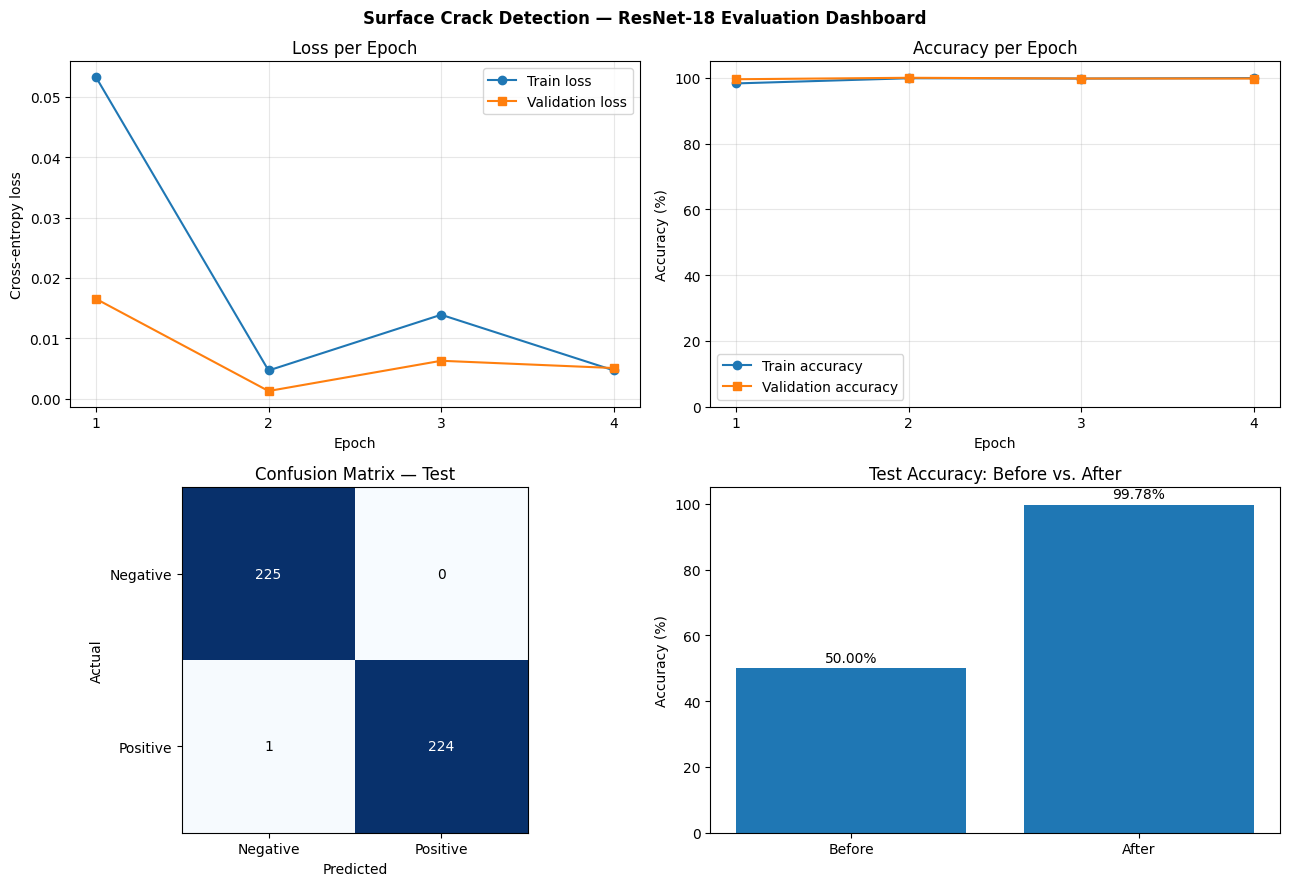

Saved dashboard.png


In [ ]:
# Cell 5 — Create the training/evaluation dashboard

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle('Surface Crack Detection — ResNet-18 Evaluation Dashboard', fontweight='bold')
epochs = range(1, EPOCHS + 1)

axes[0, 0].plot(epochs, history['train_loss'], marker='o', label='Train loss')
axes[0, 0].plot(epochs, history['val_loss'], marker='s', label='Validation loss')
axes[0, 0].set(title='Loss per Epoch', xlabel='Epoch', ylabel='Cross-entropy loss')
axes[0, 0].set_xticks(list(epochs))
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

axes[0, 1].plot(epochs, np.array(history['train_acc']) * 100, marker='o', label='Train accuracy')
axes[0, 1].plot(epochs, np.array(history['val_acc']) * 100, marker='s', label='Validation accuracy')
axes[0, 1].set(title='Accuracy per Epoch', xlabel='Epoch', ylabel='Accuracy (%)', ylim=(0, 105))
axes[0, 1].set_xticks(list(epochs))
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

cm = after_metrics['Confusion Matrix']
axes[1, 0].imshow(cm, cmap='Blues')
axes[1, 0].set(title='Confusion Matrix — Test', xlabel='Predicted', ylabel='Actual')
axes[1, 0].set_xticks(range(2), class_names)
axes[1, 0].set_yticks(range(2), class_names)
for row in range(2):
    for col in range(2):
        axes[1, 0].text(col, row, str(cm[row, col]), ha='center', va='center',
                        color='white' if cm[row, col] > cm.max() / 2 else 'black')

bars = axes[1, 1].bar(['Before', 'After'],
                       [before_metrics['Accuracy'] * 100, after_metrics['Accuracy'] * 100])
axes[1, 1].set(title='Test Accuracy: Before vs. After', ylabel='Accuracy (%)', ylim=(0, 105))
for bar in bars:
    axes[1, 1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 2,
                    f'{bar.get_height():.2f}%', ha='center')
plt.tight_layout()
plt.savefig('dashboard.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved dashboard.png')

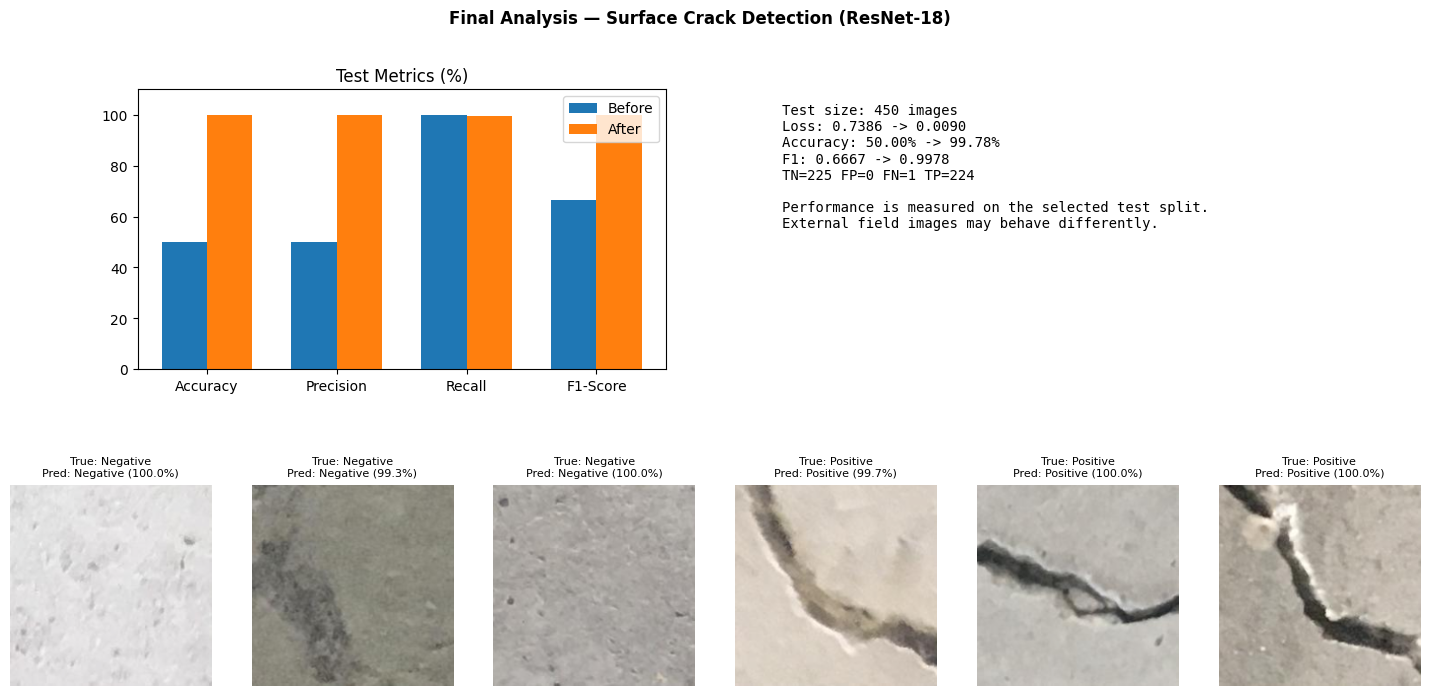

Saved final_analysis.png


In [ ]:
# Cell 6 — Save final analysis and display balanced sample predictions

model.eval()
negative_samples, positive_samples = [], []
with torch.inference_mode():
    for images, labels in test_loader:
        images_device = images.to(device)
        probabilities = torch.softmax(model(images_device), dim=1).cpu()
        predictions = probabilities.argmax(dim=1)
        for idx in range(len(labels)):
            sample = (images[idx], int(labels[idx]), int(predictions[idx]),
                      float(probabilities[idx, predictions[idx]]))
            if labels[idx].item() == 0 and len(negative_samples) < 3:
                negative_samples.append(sample)
            elif labels[idx].item() == 1 and len(positive_samples) < 3:
                positive_samples.append(sample)
        if len(negative_samples) == 3 and len(positive_samples) == 3:
            break
samples = negative_samples + positive_samples

fig = plt.figure(figsize=(15, 8))
fig.suptitle('Final Analysis — Surface Crack Detection (ResNet-18)', fontweight='bold')
ax1 = fig.add_subplot(2, 2, 1)
names = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
x = np.arange(len(names))
width = 0.35
ax1.bar(x - width / 2, [before_metrics[k] * 100 for k in names], width, label='Before')
ax1.bar(x + width / 2, [after_metrics[k] * 100 for k in names], width, label='After')
ax1.set_xticks(x, names)
ax1.set_ylim(0, 110)
ax1.set_title('Test Metrics (%)')
ax1.legend()

ax2 = fig.add_subplot(2, 2, 2)
ax2.axis('off')
summary = (f'Test size: {len(test_ds)} images\n'
           f'Loss: {before_metrics["Loss"]:.4f} -> {after_metrics["Loss"]:.4f}\n'
           f'Accuracy: {before_metrics["Accuracy"]:.2%} -> {after_metrics["Accuracy"]:.2%}\n'
           f'F1: {before_metrics["F1-Score"]:.4f} -> {after_metrics["F1-Score"]:.4f}\n'
           f'TN={cm[0,0]} FP={cm[0,1]} FN={cm[1,0]} TP={cm[1,1]}\n\n'
           'Performance is measured on the selected test split.\n'
           'External field images may behave differently.')
ax2.text(0.02, 0.95, summary, va='top', family='monospace', fontsize=10)

sample_grid = fig.add_gridspec(1, 6, left=0.04, right=0.98, top=0.43, bottom=0.09)
for j, (image, truth, pred, confidence) in enumerate(samples):
    ax = fig.add_subplot(sample_grid[0, j])
    ax.imshow(unnormalize(image))
    ax.set_title(f'True: {class_names[truth]}\nPred: {class_names[pred]} ({confidence:.1%})',
                 fontsize=8)
    ax.axis('off')
plt.savefig('final_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved final_analysis.png')

## Interpretation and limitations

- The **before-training** measurement is taken after replacing the pretrained ResNet-18's final layer but **before any optimizer step**.
- Both test measurements use the **same held-out test images and the same `evaluate_model` function**.
- Train and validation curves are tracked for every epoch. The test set is not part of the optimization process.
- Exact duplicates are checked between the splits, but **near-duplicate images, shared capture sessions, or images from the same wall/road** may still cause optimistic estimates. If source IDs are available, use a group-based split instead.
- A high score on this dataset does **not** establish real-world performance under different illumination, blur, weather, or camera conditions. The model classifies whole images; it does not localize cracks.